In [4]:
import import_ipynb
from Recodificacion import *

In [5]:
import import_ipynb
from Codigos_obj import load_np, match_size_np, _validate_size

Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]


c:\Users\santi\Jeremias\TrabajoGrado\Codigos\Funciones_Matematicas\Generar_Dataset\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\santi\Jeremias\TrabajoGrado\Codigos\Funciones_Matematicas\Generar_Dataset\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: c:\Users\santi\Jeremias\TrabajoGrado\Codigos\Funciones_Matematicas\Generar_Dataset\lib\site-packages\lpips\weights\v0.1\vgg.pth
Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]
Loading model from: c:\Users\santi\Jeremias\TrabajoGrado\Codigos\Funciones_Matematicas\Generar_Dataset\lib\site-packages\lpips\weights\v0.1\vgg.pth


In [ ]:
import warnings
import time
import torch
import numpy as np
from skimage import io, color
from skimage.transform import resize
import lpips
from pytorch_msssim import ms_ssim


# Recodificación


In [6]:
import os
import random

def generar_pruebas_conversion():

    base_dir = "imagenes_prueba"

    formatos = ["jpg", "png", "webp"]

    metodos = {
        "imagemagick": convert_with_imagemagick,
        "pillow": convert_image_pillow,
        "ffmpeg": convert_with_ffmpeg
    }

    for formato_origen in formatos:

        carpeta_origen = os.path.join(base_dir, formato_origen)

        if not os.path.exists(carpeta_origen):
            print(f"[ERROR] No existe: {carpeta_origen}")
            continue

        # ------------------------------------------------
        # IMÁGENES
        # ------------------------------------------------

        imagenes = [
            f for f in os.listdir(carpeta_origen)
            if os.path.isfile(os.path.join(carpeta_origen, f))
        ]

        if len(imagenes) < 18:
            raise ValueError(
                f"Se requieren mínimo 18 imágenes en {carpeta_origen}"
            )

        random.shuffle(imagenes)

        # ------------------------------------------------
        # DIVISIÓN 6 / 6 / 6
        # ------------------------------------------------

        grupos = {
            "imagemagick": imagenes[0:6],
            "pillow": imagenes[6:12],
            "ffmpeg": imagenes[12:18]
        }

        # ------------------------------------------------
        # FORMATOS DESTINO
        # ------------------------------------------------

        formatos_destino = [
            f for f in formatos
            if f != formato_origen
        ]

        formato_a = formatos_destino[0]
        formato_b = formatos_destino[1]

        # ------------------------------------------------
        # CONVERSIÓN
        # ------------------------------------------------

        for metodo_nombre, archivos in grupos.items():

            funcion_conversion = metodos[metodo_nombre]

            # 3 imágenes al formato A
            grupo_a = archivos[:3]

            # 3 imágenes al formato B
            grupo_b = archivos[3:]

            # ============================================
            # FORMATO A
            # ============================================

            for archivo in grupo_a:

                input_path = os.path.join(
                    carpeta_origen,
                    archivo
                )

                nombre = os.path.splitext(archivo)[0]

                out_dir = os.path.join(
                    base_dir,
                    metodo_nombre,
                    formato_a
                )

                os.makedirs(out_dir, exist_ok=True)

                output_path = os.path.join(
                    out_dir,
                    f"{nombre}.{formato_a}"
                )

                funcion_conversion(
                    input_path,
                    output_path,
                    quality=90
                )

                print(
                    f"[OK] {archivo} | "
                    f"{formato_origen} → {formato_a} | "
                    f"{metodo_nombre}"
                )

            # ============================================
            # FORMATO B
            # ============================================

            for archivo in grupo_b:

                input_path = os.path.join(
                    carpeta_origen,
                    archivo
                )

                nombre = os.path.splitext(archivo)[0]

                out_dir = os.path.join(
                    base_dir,
                    metodo_nombre,
                    formato_b
                )

                os.makedirs(out_dir, exist_ok=True)

                output_path = os.path.join(
                    out_dir,
                    f"{nombre}.{formato_b}"
                )

                funcion_conversion(
                    input_path,
                    output_path,
                    quality=90
                )

                print(
                    f"[OK] {archivo} | "
                    f"{formato_origen} → {formato_b} | "
                    f"{metodo_nombre}"
                )

In [3]:
generar_pruebas_conversion()

[ImageMagick] Convertido → imagenes_prueba\imagemagick\png\COCO_test2014_000000003359.png
[OK] COCO_test2014_000000003359.jpg | jpg → png | imagemagick
[ImageMagick] Convertido → imagenes_prueba\imagemagick\png\COCO_test2014_000000004035.png
[OK] COCO_test2014_000000004035.jpg | jpg → png | imagemagick
[ImageMagick] Convertido → imagenes_prueba\imagemagick\png\COCO_test2014_000000002490.png
[OK] COCO_test2014_000000002490.jpg | jpg → png | imagemagick
[ImageMagick] Convertido → imagenes_prueba\imagemagick\webp\COCO_test2014_000000003376.webp
[OK] COCO_test2014_000000003376.jpg | jpg → webp | imagemagick
[ImageMagick] Convertido → imagenes_prueba\imagemagick\webp\COCO_test2014_000000007324.webp
[OK] COCO_test2014_000000007324.jpg | jpg → webp | imagemagick
[ImageMagick] Convertido → imagenes_prueba\imagemagick\webp\COCO_test2014_000000002922.webp
[OK] COCO_test2014_000000002922.jpg | jpg → webp | imagemagick
Convertido: imagenes_prueba\jpg\COCO_test2014_000000002059.jpg → imagenes_prueb

In [7]:
def obtener_pares_imagenes(base_dir):
    """
    Estructura esperada:
    base_dir/
    ├── jpg/        ← originales .jpg
    ├── png/        ← originales .png
    ├── webp/       ← originales .webp
    ├── pillow/
    │   ├── jpg/    ← recodificadas .jpg
    │   ├── png/    ← recodificadas .png
    │   └── webp/   ← recodificadas .webp
    ├── ffmpeg/
    │   ├── jpg/
    │   ├── png/
    │   └── webp/
    └── imagemagick/
        ├── jpg/
        ├── png/
        └── webp/
    """

    METODOS   = ["pillow", "ffmpeg", "imagemagick"]
    FORMATOS  = ["jpg", "png", "webp"]
    EXTENSIONES = {".jpg", ".jpeg", ".png", ".webp"}

    pares = []

    for metodo in METODOS:
        for formato_comp in FORMATOS:

            carpeta_comp = os.path.join(base_dir, metodo, formato_comp)

            if not os.path.isdir(carpeta_comp):
                continue

            for archivo_comp in os.listdir(carpeta_comp):

                ext = os.path.splitext(archivo_comp)[1].lower()
                if ext not in EXTENSIONES:
                    continue

                # Nombre base sin extensión
                nombre_base = os.path.splitext(archivo_comp)[0]

                # Buscar original en las 3 carpetas de origen
                path_comp = os.path.join(carpeta_comp, archivo_comp)
                path_orig = None

                for formato_orig in FORMATOS:
                    for ext_orig in EXTENSIONES:
                        candidato = os.path.join(
                            base_dir,
                            formato_orig,
                            f"{nombre_base}{ext_orig}"
                        )
                        if os.path.exists(candidato):
                            path_orig = candidato
                            break
                    if path_orig:
                        break

                if path_orig:
                    pares.append((path_orig, path_comp, metodo, formato_comp))
                else:
                    print(f"  ⚠ Sin original para: {archivo_comp}")

    print(f"✅ {len(pares)} pares encontrados")
    return pares

In [8]:
pares = obtener_pares_imagenes("Imagenes_prueba")

# Cada par tiene: (original, comprimida, metodo, formato)
for orig, comp, metodo, formato in pares[:3]:
    print(f"{metodo} | {formato} | {os.path.basename(orig)} → {os.path.basename(comp)}")

✅ 54 pares encontrados
pillow | jpg | 00000004_300resized (2).png → 00000004_300resized (2).jpg
pillow | jpg | 00000005_512resized.png → 00000005_512resized.jpg
pillow | jpg | 5a330e7b3.png → 5a330e7b3.jpg


In [12]:
def calcular_ms_ssim_lpips(
    img_orig_path: str,
    img_comp_path: str,
    alpha: float = 0.5,
    beta: float = 0.5,
    silent_resize: bool = False,
    loss_fn_override=None,    # ← nuevo
    device_override=None,     # ← nuevo
) -> dict:

    # Usa los overrides si se pasan, sino usa las variables globales
    _loss_fn = loss_fn_override if loss_fn_override is not None else loss_fn
    _device  = device_override  if device_override  is not None else device

    if not (0.0 <= alpha <= 1.0 and 0.0 <= beta <= 1.0):
        raise ValueError("alpha y beta deben estar en [0, 1].")

    arr_o = load_np(img_orig_path)
    arr_c = load_np(img_comp_path)
    arr_o, arr_c = match_size_np(arr_o, arr_c, silent=silent_resize)

    _validate_size(arr_o, "Imagen original")
    _validate_size(arr_c, "Imagen comprimida")

    with torch.no_grad():

        t_o = torch.from_numpy(arr_o / 255.0).permute(2, 0, 1).unsqueeze(0).float().to(_device)
        t_c = torch.from_numpy(arr_c / 255.0).permute(2, 0, 1).unsqueeze(0).float().to(_device)

        ms = ms_ssim(t_o, t_c, data_range=1.0, size_average=True).item()

        lp_o = (t_o * 2.0) - 1.0
        lp_c = (t_c * 2.0) - 1.0

        lp_raw = _loss_fn(lp_o, lp_c).item()

    lp_norm = 1.0 / (1.0 + lp_raw)
    score   = alpha * ms + beta * lp_norm

    return {
        'ms_ssim':    round(ms, 6),
        'lpips_raw':  round(lp_raw, 6),
        'lpips_norm': round(lp_norm, 6),
        'combinado':  round(score, 6),
    }

In [16]:
import os
import time
import torch
import lpips
import pandas as pd

# =========================================================
# BENCHMARK LPIPS
# =========================================================

def benchmark_lpips(
    pares_imagenes,
    cantidades=[1, 5, 10, 18, 54]
):

    resultados = []

    modelos = [
        "alex",
        "vgg",
        "squeeze"
    ]

    devices = ["cpu"]

    if torch.cuda.is_available():
        devices.append("cuda")

    # =====================================================
    # LOOP MODELOS
    # =====================================================

    for modelo in modelos:

        # =================================================
        # LOOP DEVICE
        # =================================================

        for dev in devices:

            print(f"\n{'='*70}")
            print(f"MODELO: {modelo.upper()} | DEVICE: {dev.upper()}")
            print(f"{'='*70}")

            # -------------------------------------------------
            # CARGA MODELO
            # -------------------------------------------------

            try:

                inicio_carga = time.perf_counter()

                _device = torch.device(dev)

                _loss_fn = lpips.LPIPS(
                    net=modelo
                ).to(_device)

                _loss_fn.eval()

                for p in _loss_fn.parameters():
                    p.requires_grad_(False)

                tiempo_carga = (
                    time.perf_counter() - inicio_carga
                )

                print(
                    f"⏱ Modelo cargado en "
                    f"{tiempo_carga:.4f}s"
                )

            except Exception as e:

                print(
                    f"❌ Error cargando modelo "
                    f"{modelo}: {e}"
                )

                continue

            # =================================================
            # LOOP CANTIDADES
            # =================================================

            for n in cantidades:

                if n > len(pares_imagenes):

                    print(
                        f"⚠ Solo existen "
                        f"{len(pares_imagenes)} pares"
                    )

                    continue

                subset = pares_imagenes[:n]

                errores = 0

                inicio_total = time.perf_counter()

                # =============================================
                # LOOP PARES
                # =============================================

                for (
                    img_orig,
                    img_comp,
                    metodo,
                    formato
                ) in subset:

                    try:

                        calcular_ms_ssim_lpips(
                            img_orig,
                            img_comp,
                            loss_fn_override=_loss_fn,
                            device_override=_device
                        )

                    except Exception as e:

                        errores += 1

                        print(
                            f"❌ "
                            f"{os.path.basename(img_comp)} "
                            f"| {metodo} "
                            f"| {formato} "
                            f"| {e}"
                        )

                # ---------------------------------------------
                # SINCRONIZAR GPU
                # ---------------------------------------------

                if dev == "cuda":
                    torch.cuda.synchronize()

                tiempo_total = (
                    time.perf_counter() - inicio_total
                )

                exitosas = n - errores

                tiempo_promedio = (
                    tiempo_total / exitosas
                    if exitosas > 0 else 0
                )

                img_seg = (
                    exitosas / tiempo_total
                    if tiempo_total > 0 else 0
                )

                # =============================================
                # EXTRAER ESTADÍSTICAS DE FORMATO
                # =============================================

                formatos_subset = [
                    x[3] for x in subset
                ]

                jpgs = formatos_subset.count("jpg")
                pngs = formatos_subset.count("png")
                webps = formatos_subset.count("webp")

                # =============================================
                # PRINT
                # =============================================

                print(
                    f"[{modelo.upper()} | {dev.upper()}] "
                    f"{n} imgs | "
                    f"{tiempo_total:.4f}s total | "
                    f"{tiempo_promedio:.4f}s/img | "
                    f"{img_seg:.2f} img/s | "
                    f"errores={errores}"
                )

                # =============================================
                # RESULTADOS
                # =============================================

                resultados.append({

                    "modelo":
                        modelo,

                    "device":
                        dev,

                    "imagenes":
                        n,

                    "exitosas":
                        exitosas,

                    "errores":
                        errores,

                    "jpg":
                        jpgs,

                    "png":
                        pngs,

                    "webp":
                        webps,

                    "tiempo_total_s":
                        round(tiempo_total, 4),

                    "tiempo_promedio_s":
                        round(tiempo_promedio, 6),

                    "tiempo_carga_s":
                        round(tiempo_carga, 4),

                    "img_por_segundo":
                        round(img_seg, 2)
                })

            # =================================================
            # LIMPIAR GPU
            # =================================================

            del _loss_fn

            if dev == "cuda":
                torch.cuda.empty_cache()

    # =====================================================
    # DATAFRAME
    # =====================================================

    df = pd.DataFrame(resultados)

    print(f"\n{'='*70}")
    print("RESUMEN FINAL")
    print(f"{'='*70}")

    print(
        df[
            [
                "modelo",
                "device",
                "imagenes",
                "jpg",
                "png",
                "webp",
                "tiempo_promedio_s",
                "img_por_segundo"
            ]
        ].to_string(index=False)
    )

    return df

In [17]:
import time
df = benchmark_lpips(
    pares,
    cantidades=[1, 5, 10, 18, 54]
)


MODELO: ALEX | DEVICE: CPU
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


c:\Users\santi\Jeremias\TrabajoGrado\Codigos\Funciones_Matematicas\Generar_Dataset\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\santi\Jeremias\TrabajoGrado\Codigos\Funciones_Matematicas\Generar_Dataset\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: c:\Users\santi\Jeremias\TrabajoGrado\Codigos\Funciones_Matematicas\Generar_Dataset\lib\site-packages\lpips\weights\v0.1\alex.pth
⏱ Modelo cargado en 0.2864s
[ALEX | CPU] 1 imgs | 0.1420s total | 0.1420s/img | 7.04 img/s | errores=0
[ALEX | CPU] 5 imgs | 0.9011s total | 0.1802s/img | 5.55 img/s | errores=0
[ALEX | CPU] 10 imgs | 1.8061s total | 0.1806s/img | 5.54 img/s | errores=0
[ALEX | CPU] 18 imgs | 2.9568s total | 0.1643s/img | 6.09 img/s | errores=0
[ALEX | CPU] 54 imgs | 8.9939s total | 0.1666s/img | 6.00 img/s | errores=0

MODELO: ALEX | DEVICE: CUDA
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


c:\Users\santi\Jeremias\TrabajoGrado\Codigos\Funciones_Matematicas\Generar_Dataset\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\santi\Jeremias\TrabajoGrado\Codigos\Funciones_Matematicas\Generar_Dataset\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: c:\Users\santi\Jeremias\TrabajoGrado\Codigos\Funciones_Matematicas\Generar_Dataset\lib\site-packages\lpips\weights\v0.1\alex.pth
⏱ Modelo cargado en 0.3315s
[ALEX | CUDA] 1 imgs | 0.6691s total | 0.6691s/img | 1.49 img/s | errores=0
[ALEX | CUDA] 5 imgs | 0.4702s total | 0.0940s/img | 10.63 img/s | errores=0
[ALEX | CUDA] 10 imgs | 0.7399s total | 0.0740s/img | 13.51 img/s | errores=0
[ALEX | CUDA] 18 imgs | 1.2543s total | 0.0697s/img | 14.35 img/s | errores=0
[ALEX | CUDA] 54 imgs | 3.6163s total | 0.0670s/img | 14.93 img/s | errores=0

MODELO: VGG | DEVICE: CPU
Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]


...

Loading model from: c:\Users\santi\Jeremias\TrabajoGrado\Codigos\Funciones_Matematicas\Generar_Dataset\lib\site-packages\lpips\weights\v0.1\vgg.pth
⏱ Modelo cargado en 1.6914s
[VGG | CUDA] 1 imgs | 0.2856s total | 0.2856s/img | 3.50 img/s | errores=0
[VGG | CUDA] 5 imgs | 2.0576s total | 0.4115s/img | 2.43 img/s | errores=0
[VGG | CUDA] 10 imgs | 7.4869s total | 0.7487s/img | 1.34 img/s | errores=0
[VGG | CUDA] 18 imgs | 6.0885s total | 0.3383s/img | 2.96 img/s | errores=0
[VGG | CUDA] 54 imgs | 18.0842s total | 0.3349s/img | 2.99 img/s | errores=0

MODELO: SQUEEZE | DEVICE: CPU
Setting up [LPIPS] perceptual loss: trunk [squeeze], v[0.1], spatial [off]
Loading model from: c:\Users\santi\Jeremias\TrabajoGrado\Codigos\Funciones_Matematicas\Generar_Dataset\lib\site-packages\lpips\weights\v0.1\squeeze.pth
⏱ Modelo cargado en 0.0635s
[SQUEEZE | CPU] 1 imgs | 0.0704s total | 0.0704s/img | 14.20 img/s | errores=0


c:\Users\santi\Jeremias\TrabajoGrado\Codigos\Funciones_Matematicas\Generar_Dataset\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\santi\Jeremias\TrabajoGrado\Codigos\Funciones_Matematicas\Generar_Dataset\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=SqueezeNet1_1_Weights.IMAGENET1K_V1`. You can also use `weights=SqueezeNet1_1_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


[SQUEEZE | CPU] 5 imgs | 1.3159s total | 0.2632s/img | 3.80 img/s | errores=0
[SQUEEZE | CPU] 10 imgs | 2.7281s total | 0.2728s/img | 3.67 img/s | errores=0
[SQUEEZE | CPU] 18 imgs | 4.4882s total | 0.2493s/img | 4.01 img/s | errores=0
[SQUEEZE | CPU] 54 imgs | 13.1957s total | 0.2444s/img | 4.09 img/s | errores=0

MODELO: SQUEEZE | DEVICE: CUDA
Setting up [LPIPS] perceptual loss: trunk [squeeze], v[0.1], spatial [off]
Loading model from: c:\Users\santi\Jeremias\TrabajoGrado\Codigos\Funciones_Matematicas\Generar_Dataset\lib\site-packages\lpips\weights\v0.1\squeeze.pth
⏱ Modelo cargado en 0.0318s


c:\Users\santi\Jeremias\TrabajoGrado\Codigos\Funciones_Matematicas\Generar_Dataset\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\santi\Jeremias\TrabajoGrado\Codigos\Funciones_Matematicas\Generar_Dataset\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=SqueezeNet1_1_Weights.IMAGENET1K_V1`. You can also use `weights=SqueezeNet1_1_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


[SQUEEZE | CUDA] 1 imgs | 0.2361s total | 0.2361s/img | 4.24 img/s | errores=0
[SQUEEZE | CUDA] 5 imgs | 0.4278s total | 0.0856s/img | 11.69 img/s | errores=0
[SQUEEZE | CUDA] 10 imgs | 0.8306s total | 0.0831s/img | 12.04 img/s | errores=0
[SQUEEZE | CUDA] 18 imgs | 1.4219s total | 0.0790s/img | 12.66 img/s | errores=0
[SQUEEZE | CUDA] 54 imgs | 4.1594s total | 0.0770s/img | 12.98 img/s | errores=0

RESUMEN FINAL
 modelo device  imagenes  jpg  png  webp  tiempo_promedio_s  img_por_segundo
   alex    cpu         1    1    0     0           0.141997             7.04
   alex    cpu         5    5    0     0           0.180217             5.55
   alex    cpu        10    6    4     0           0.180610             5.54
   alex    cpu        18    6    6     6           0.164268             6.09
   alex    cpu        54   18   18    18           0.166553             6.00
   alex   cuda         1    1    0     0           0.669063             1.49
   alex   cuda         5    5    0     0    

In [18]:
df

,modelo,device,imagenes,exitosas,errores,jpg,png,webp,tiempo_total_s,tiempo_promedio_s,tiempo_carga_s,img_por_segundo
0,alex,cpu,1,1,0,1,0,0,0.1420,0.141997,0.2864,7.04
1,alex,cpu,5,5,0,5,0,0,0.9011,0.180217,0.2864,5.55
2,alex,cpu,10,10,0,6,4,0,1.8061,0.180610,0.2864,5.54
3,alex,cpu,18,18,0,6,6,6,2.9568,0.164268,0.2864,6.09
4,alex,cpu,54,54,0,18,18,18,8.9939,0.166553,0.2864,6.00
5,alex,cuda,1,1,0,1,0,0,0.6691,0.669063,0.3315,1.49
6,alex,cuda,5,5,0,5,0,0,0.4702,0.094034,0.3315,10.63
7,alex,cuda,10,10,0,6,4,0,0.7399,0.073994,0.3315,13.51
8,alex,cuda,18,18,0,6,6,6,1.2543,0.069686,0.3315,14.35
9,alex,cuda,54,54,0,18,18,18,3.6163,0.066969,0.3315,14.93


In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

def graficar_benchmark(df: pd.DataFrame):
    """
    Genera 4 gráficas comparativas del benchmark LPIPS.
    """

    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle("Benchmark LPIPS — Comparación de Modelos y Dispositivos", 
                 fontsize=16, fontweight="bold", y=1.01)

    colores = {
        "alex":    "#4C72B0",
        "vgg":     "#DD8452",
        "squeeze": "#55A868"
    }

    estilos = {
        "cpu":  "-o",
        "cuda": "--s"
    }

    # ─────────────────────────────────────────────
    # 1. Tiempo promedio por imagen (s)
    # ─────────────────────────────────────────────
    ax1 = axes[0, 0]

    for modelo in df["modelo"].unique():
        for device in df["device"].unique():
            subset = df[(df["modelo"] == modelo) & (df["device"] == device)]
            if subset.empty:
                continue
            label = f"{modelo.upper()} | {device.upper()}"
            ax1.plot(
                subset["imagenes"],
                subset["tiempo_promedio_s"],
                estilos[device],
                color=colores[modelo],
                label=label,
                linewidth=2,
                markersize=7,
                linestyle="--" if device == "cuda" else "-"
            )

    ax1.set_title("Tiempo promedio por imagen", fontsize=13)
    ax1.set_xlabel("Número de imágenes")
    ax1.set_ylabel("Tiempo (s/imagen)")
    ax1.legend(fontsize=8, loc="upper right")
    ax1.grid(True, alpha=0.3)

    # ─────────────────────────────────────────────
    # 2. Imágenes por segundo
    # ─────────────────────────────────────────────
    ax2 = axes[0, 1]

    for modelo in df["modelo"].unique():
        for device in df["device"].unique():
            subset = df[(df["modelo"] == modelo) & (df["device"] == device)]
            if subset.empty:
                continue
            label = f"{modelo.upper()} | {device.upper()}"
            ax2.plot(
                subset["imagenes"],
                subset["img_por_segundo"],
                color=colores[modelo],
                label=label,
                linewidth=2,
                markersize=7,
                linestyle="--" if device == "cuda" else "-",
                marker="s" if device == "cuda" else "o"
            )

    ax2.set_title("Throughput (imágenes por segundo)", fontsize=13)
    ax2.set_xlabel("Número de imágenes")
    ax2.set_ylabel("img/s")
    ax2.legend(fontsize=8, loc="upper left")
    ax2.grid(True, alpha=0.3)

    # ─────────────────────────────────────────────
    # 3. Tiempo de carga del modelo (barras)
    # ─────────────────────────────────────────────
    ax3 = axes[1, 0]

    carga_df = df[["modelo", "device", "tiempo_carga_s"]].drop_duplicates()

    modelos   = carga_df["modelo"].unique()
    devices   = carga_df["device"].unique()
    x         = np.arange(len(modelos))
    ancho     = 0.35
    offset    = -(len(devices) - 1) * ancho / 2

    for i, device in enumerate(devices):
        subset = carga_df[carga_df["device"] == device]
        tiempos = [
            subset[subset["modelo"] == m]["tiempo_carga_s"].values[0]
            if len(subset[subset["modelo"] == m]) > 0 else 0
            for m in modelos
        ]
        bars = ax3.bar(
            x + offset + i * ancho,
            tiempos,
            ancho,
            label=device.upper(),
            alpha=0.85,
            color=["#4C72B0", "#DD8452", "#55A868"][:len(modelos)]
            if device == "cpu" else ["#9DB8D2", "#EDBB99", "#99CBA8"][:len(modelos)]
        )
        for bar, val in zip(bars, tiempos):
            ax3.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.01,
                f"{val:.3f}s",
                ha="center", va="bottom", fontsize=8
            )

    ax3.set_title("Tiempo de carga del modelo", fontsize=13)
    ax3.set_xlabel("Modelo")
    ax3.set_ylabel("Tiempo (s)")
    ax3.set_xticks(x)
    ax3.set_xticklabels([m.upper() for m in modelos])
    ax3.legend(fontsize=9)
    ax3.grid(True, alpha=0.3, axis="y")

    # ─────────────────────────────────────────────
    # 4. Tiempo total acumulado (18 imágenes)
    # ─────────────────────────────────────────────
    ax4 = axes[1, 1]

    df_18 = df[df["imagenes"] == df["imagenes"].max()].copy()
    df_18["etiqueta"] = df_18["modelo"].str.upper() + "\n" + df_18["device"].str.upper()

    colores_barras = [
        colores.get(m, "#888888")
        for m in df_18["modelo"]
    ]
    alphas = [0.6 if d == "cuda" else 1.0 for d in df_18["device"]]

    bars = ax4.bar(
        df_18["etiqueta"],
        df_18["tiempo_total_s"],
        color=colores_barras,
        alpha=0.85,
        edgecolor="black",
        linewidth=0.7
    )

    for bar, val in zip(bars, df_18["tiempo_total_s"]):
        ax4.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.005,
            f"{val:.3f}s",
            ha="center", va="bottom", fontsize=8
        )

    ax4.set_title(f"Tiempo total ({df['imagenes'].max()} imágenes)", fontsize=13)
    ax4.set_xlabel("Modelo | Dispositivo")
    ax4.set_ylabel("Tiempo total (s)")
    ax4.grid(True, alpha=0.3, axis="y")

    plt.tight_layout()
    plt.savefig("benchmark_comparacion.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("✅ Gráfica guardada: benchmark_comparacion.png")

C:\Users\santi\AppData\Local\Temp\ipykernel_18352\2634982914.py:37: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-o" (-> linestyle='-'). The keyword argument will take precedence.
  ax1.plot(
C:\Users\santi\AppData\Local\Temp\ipykernel_18352\2634982914.py:37: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "--s" (-> linestyle='--'). The keyword argument will take precedence.
  ax1.plot(


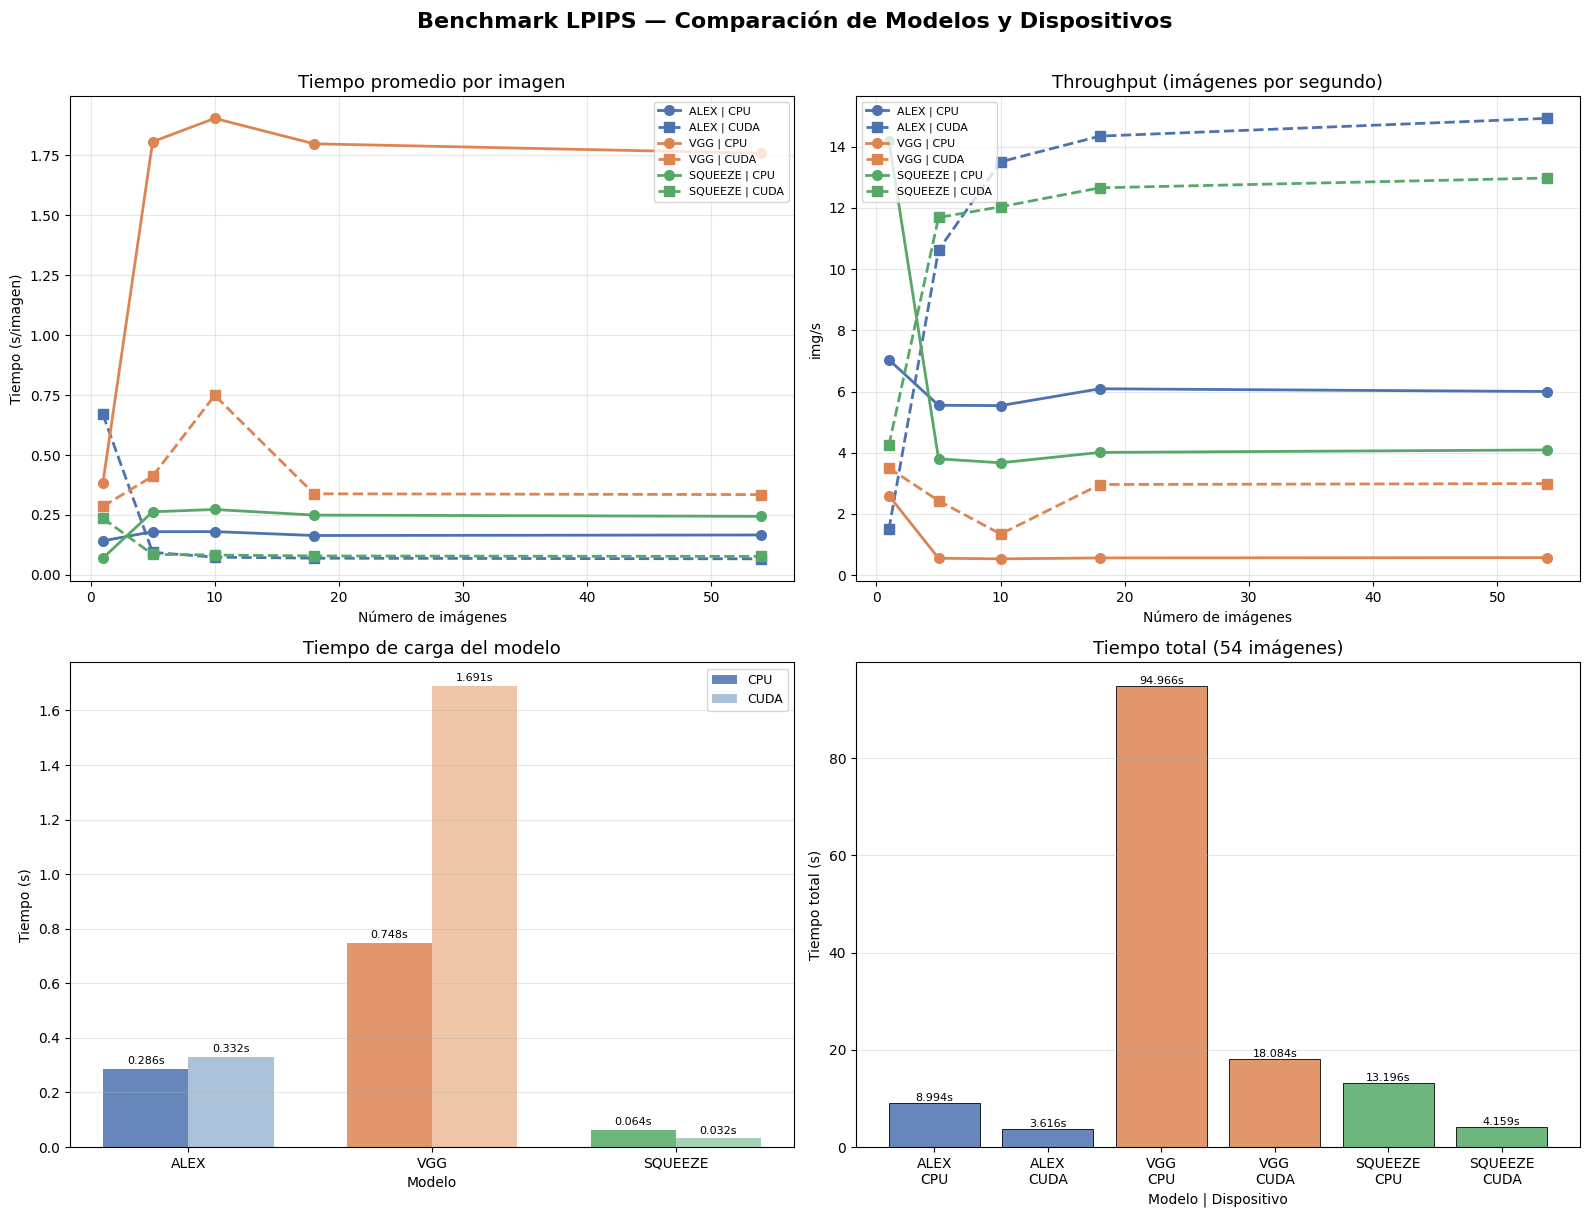

✅ Gráfica guardada: benchmark_comparacion.png


In [20]:
graficar_benchmark(df)